# Тестирование и логгирование

Для начала поговорим про тестирование. Для чего нужно тестирование?

Пирамида тестирования - один из способов обеспечения качества ПО, визуализация, которая помогает группировать тесты по типу их назначения. Так же, позволяет согласовать правила написания тестов, разделения их на типы, обозначить основной фокус тестирования в каждой из групп.

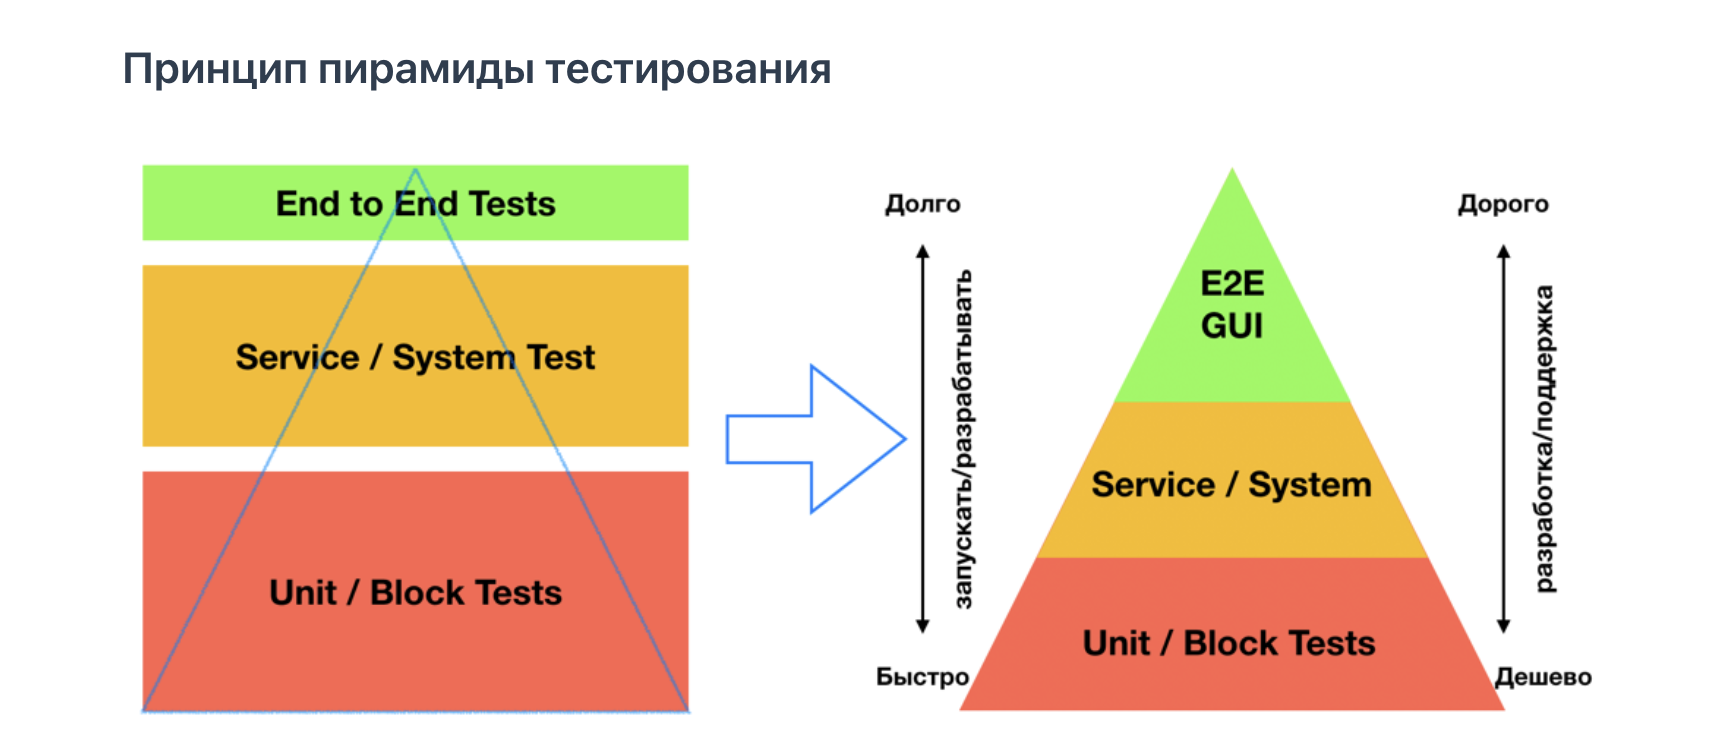

## Категории тестов

* Юнит-тесты
* Системные тесты (они же интеграционные)
* e2e (end-to-end) тестирование

### Unit Testing

* находятся на самой нижней частей пирамиды и являются основой всех тестов
* тесты проверяют отдельные компоненты (классы, функции и тд) наименьшие единицы программного обеспечения
* главная задача: выявить мелкие баги и ускорить процесс разработки и погружения новых участников проекта в уже написанный код

**Пример:** Тестирование логики функции фильтрации входящего запроса

### Integration Testing

* средний уровень в пирамиде 
* тесты помогают проверять как различные системы взаимодействуют между собой
* при написании их тестируются случаи зависящие косвенно от разработчика (к примеру внешняя система не отвечает и мы не должны этот случай обрабатывать!)

#### Что может представлять из себя внешняя система?

Все системы которые не могут поддерживаться разработчиками.

* внешнее API
* база данных


**Пример:** Тестирование методов или функций которые взаимодействуют с базой данных. 

Примечание. Если при тестировании функции все внепроцессные зависимости в нашей функции заменить Mock объектами, которые будут симулировать такие зависимости, а не выполнять их в реальности, то мы получим уже unit тестирование этой функции.  

Юнит-тесты работают по принципу «тестирование компонента в изоляции», в то время как
интеграционные тесты проверяют работу различных компонентов вкупе, зачастую интеграционные тесты
отвечают функциональным требованиям непосредственно.

Соотношение между unit и интеграционными тестами зависит от особенностей проекта, но ***общее правило выглядит так***: проверьте как можно больше пограничных случаев бизнес-сценария юнит-тестами; используйте интеграционные тесты для покрытия одного позитивного пути, а также всех граничных случаев, которые не покрываются юнит-тестами.

### E2E Testing

* находятся на вершине пирамиды и являются самыми дорогими по времени выполнения
* тесты эмулируют взаимодействие пользователя с системой через UI или интефейс API (swagger) проверяя, что все компоненты работют как ожидается 
* проводятся реже т.к. дорогие и требует много времени физических и нефизических ресурсов

**Пример:** тестирование пользовательского сценария в интернет магазине от авторизации до оплаты за покупку товара попутно повторяя поведение обычного пользователя.

## Задание на сегодня: покрыть CRUD тестами

Перед вами очень простое CRUD* приложение

CRUD (сокр. от англ. create, read, update, delete — «создать, прочесть, обновить, удалить») — акроним, обозначающий четыре базовые функции, используемые при работе с персистентными хранилищами данных:

* создание
* чтение
* редактирование
* удаление

В коде ниже мы храним всех пользователей в словаре. Ключи мы генерируем сами. От пользователя ждем только обязательное поле `special_id` которое у нас будет обязательным при создании клиента. (конечно можно было придумать и внешнюю проверку отдельной функцией чтобы это как то проверять, но давайте это опустим.)

In [4]:
%%writefile simpledb.py

import typing as tp

class SimpleDB:
    def __init__(self):
        self.db = {}

    def create(self, record_id, special_id, name, surname, phone_number) -> str:
        if record_id in self.db:
            raise ValueError(f"Record with ID {record_id} already exists.")
        self.db[record_id] = {
            "special_id": special_id,
            "name": name,
            "surname": surname,
            "phone_number": phone_number
        }
        return f"Record added with ID {record_id}: {self.db[record_id]}"

    def read_all(self) -> dict[str, tp.Any]:
        if not self.db:
            return "Database is empty."
        return self.db

    def read(self, record_id: int) -> str:
        return self.db.get(record_id)

    def update(self, record_id: int, special_id: int, name=None, surname=None, phone_number=None) -> str:
        if record_id not in self.db:
            return f"Record with ID {record_id} not found."
        
        self.db[record_id]['special_id'] = special_id
        
        if name:
            self.db[record_id]['name'] = name
        if surname:
            self.db[record_id]['surname'] = surname
        if phone_number:
            self.db[record_id]['phone_number'] = phone_number
        return f"Record with ID {record_id} updated: {self.db[record_id]}"

    def delete(self, record_id: int) -> str:
        if record_id not in self.db:
            return f"Record with ID {record_id} not found."
        deleted_record = self.db.pop(record_id)
        return f"Record deleted with ID {record_id}: {deleted_record}"


Overwriting simpledb.py


In [7]:
%%writefile user_service.py

import typing as tp

from simpledb import SimpleDB

class UserService:
    def __init__(self, name: str):
        self._name = name
        self.__db = None # "private" var

    # property - способ превратить атрибуты класса в управляемые без использование get'эров и set'эров
    # атрибут становится по факту методом, но вызов этого метода происходит через обращение как к атрибуту, то есть без ()
    @property
    def _db(self) -> SimpleDB:
        if self.__db is None:
            self.__db = SimpleDB()
        return self.__db

    def _data_validation(self, **kwargs) -> None:
        if 'special_id' not in kwargs or not isinstance(kwargs['special_id'], int):
            raise ValueError("The field 'special_id' is required and must be an integer.")
        for field in ['name', 'surname', 'phone_number']:
            if field not in kwargs or not kwargs[field]:
                raise ValueError(f"The field '{field}' is required.")

    def create_new_user(self, **kwargs) -> str:
        import random
        self._data_validation(**kwargs)

        new_id = random.randint(0, int(1e9))
        while new_id in self._db.db:
            new_id = random.randint(0, int(1e9))

        self._db.create(new_id, kwargs['special_id'], kwargs['name'], kwargs['surname'], kwargs['phone_number'])
        return f"Successfully created new user with ID {new_id}"

    def get_all_users(self) -> str:
        users = self._db.read_all()
        if isinstance(users, str):
            return users
        return f"All users: {users}"

    def get_user_by_id(self, user_id):
        user = self._db.read(user_id)
        if user is None:
            raise ValueError(f"User with ID {user_id} not found.")
        return user

    def update_user(self, user_id, **kwargs):
        user_data = self.get_user_by_id(user_id)
        if user_data is None:
            raise ValueError(f"User with ID {user_id} not found.")

        for key, value in kwargs.items():
            if value is not None:
                user_data[key] = value

        updated_user = self._db.update(
            user_id,
            user_data['special_id'],
            user_data.get('name'),
            user_data.get('surname'),
            user_data.get('phone_number')
        )
        return updated_user

    def delete_user(self, user_id) -> str:
        deleted_user = self._db.delete(user_id)
        return deleted_user

Overwriting user_service.py


### Unit tests

In [131]:
from simpledb import SimpleDB
from user_service import UserService

Убедимся, что у нас нулевое покрытие тестами. Как проверить и что это такое?

Cуществует такой модуль как coverage.py в котором она индексирует все задетые и проверенные случаи в тестах приложения.

In [25]:
!pip install coverage

In [26]:
!coverage --version

Coverage.py, version 7.10.7 with C extension
Full documentation is at https://coverage.readthedocs.io/en/7.10.7


In [27]:
!pip install ipytest


In [132]:
# настроим все необходимое чтобы гонять тесты в пайбуке

import pytest
import ipytest
import coverage
ipytest.autoconfig()
__file__ = "seminar_03_solved.ipynb"

In [14]:
!coverage --help

Coverage.py, version 7.10.7 with C extension
Measure, collect, and report on code coverage in Python programs.

usage: coverage <command> [options] [args]

Commands:
    annotate    Annotate source files with execution information.
    combine     Combine a number of data files.
    debug       Display information about the internals of coverage.py
    erase       Erase previously collected coverage data.
    help        Get help on using coverage.py.
    html        Create an HTML report.
    json        Create a JSON report of coverage results.
    lcov        Create an LCOV report of coverage results.
    report      Report coverage stats on modules.
    run         Run a Python program and measure code execution.
    xml         Create an XML report of coverage results.

Use "coverage help <command>" for detailed help on any command.
Full documentation is at https://coverage.readthedocs.io/en/7.10.7


In [15]:
!coverage run --help

Usage: coverage run [options] <pyfile> [program options]

Run a Python program, measuring code execution.

Options:
  -a, --append          Append data to the data file. Otherwise it starts
                        clean each time.
  --branch              Measure branch coverage in addition to statement
                        coverage.
  --concurrency=LIBS    Properly measure code using a concurrency library.
                        Valid values are: eventlet, gevent, greenlet,
                        multiprocessing, thread, or a comma-list of them.
  --context=LABEL       The context label to record for this coverage run.
  --data-file=OUTFILE   Write the recorded coverage data to this file.
                        Defaults to '.coverage'. [env: COVERAGE_FILE]
  --include=PAT1,PAT2,...
                        Include only files whose paths match one of these
                        patterns. Accepts shell-style wildcards, which must be
                        quoted.
  -m, --module  

Проверим текущее покрытие

In [20]:
%%ipytest -q

!coverage run -m pytest
!coverage report
!coverage run --source=. --omit="*/anaconda3/*" --branch

============================= test session starts ==============================
platform darwin -- Python 3.12.5, pytest-8.4.2, pluggy-1.6.0
rootdir: /Users/a_labutin/prog/Advanced-Python-2025-2026/seminars/solved
plugins: anyio-4.11.0
collected 0 items                                                              

============================ no tests ran in 0.01s =============================
/Users/a_labutin/prog/Advanced-Python-2025-2026/hse_env/lib/python3.12/site-packages/coverage/control.py:946: CoverageWarning: No data was collected. (no-data-collected); see https://coverage.readthedocs.io/en/7.10.7/messages.html#warning-no-data-collected
  self._warn("No data was collected.", slug="no-data-collected")
No data to report.
Nothing to do.
Use 'coverage help' for help.
Full documentation is at https://coverage.readthedocs.io/en/7.10.7



Теперь давайте его покроем тестами. В первую очередь в логике мы прописывали что при создании экземляра класса мы не создаем инстанс базы данных, а только при первом использовании. Давайте убедимся в этом:

Чтобы проверить, что объект не вызывался, достаточно сделать возвращаемое значение пустым и проверить количество вызовов:

In [ ]:
"""
%%ipytest -q
%%coverage run -m pytest

import pytest
# patch - decorator which allows to patch some objects within functions
# PropertyMock - Mock class intended to be used as a property on some class
from mock import patch, PropertyMock 

from user_service import UserService

def test_db_not_initialized_until_accessed():
    # patch attributte '_db' on object UserService with Mock object PropertyMock
    with patch.object(UserService, '_db', new_callable=PropertyMock) as mock_db:
        service = UserService(name="test_service")
        
    assert mock_db.call_count == 0
"""

UsageError: Cell magic `%%coverage` not found.


In [133]:
%%writefile test_db_not_initialized_until_accessed.py

import pytest
# patch - decorator which allows to patch some objects within functions
# PropertyMock - Mock class intended to be used as a property on some class
from mock import patch, PropertyMock 

from user_service import UserService

def test_db_not_initialized_until_accessed():
    # patch attributte '_db' on object UserService with Mock object PropertyMock
    with patch.object(UserService, '_db', new_callable=PropertyMock) as mock_db:
        service = UserService(name="test_service")
        
    assert mock_db.call_count == 0

Overwriting test_db_not_initialized_until_accessed.py


In [135]:
!coverage run -m pytest ./test_db_not_initialized_until_accessed.py
#!coverage run --source=test_db_not_initialized_until_accessed -m pytest ./test_db_not_initialized_until_accessed.py

============================= test session starts ==============================
platform darwin -- Python 3.12.5, pytest-8.4.2, pluggy-1.6.0
rootdir: /Users/a_labutin/prog/Advanced-Python-2025-2026/seminars/solved
plugins: anyio-4.11.0
collected 1 item                                                               

test_db_not_initialized_until_accessed.py .                              [100%]

============================== 1 passed in 0.01s ===============================


In [136]:
"""
For each module executed, the report shows 
- the count of executable statements, 
- the number of those statements missed, 
- and the resulting coverage, expressed as a percentage.
"""
!coverage report

Name                                        Stmts   Miss  Cover
---------------------------------------------------------------
simpledb.py                                    31     23    26%
test_db_not_initialized_until_accessed.py       7      0   100%
user_service.py                                48     34    29%
---------------------------------------------------------------
TOTAL                                          86     57    34%


In [137]:
%%ipytest -q

!coverage html
!open htmlcov/index.html  # Для macOS

Wrote HTML report to ]8;;file:///Users/a_labutin/prog/Advanced-Python-2025-2026/seminars/solved/htmlcov/index.htmlhtmlcov/index.html]8;;



Мы тут подменили свойство в классе `UserService` с помощью `PropertyMock`. Это позволило нам проверять свойство `_db` сколько раз оно вызывается, и проверить, был ли объект базы данных инициализирован. По тесту мы убедились что свойство не вызывалось все как и ожидалось.

А что если захотим проверить что оно у нас сначало не вызывалось, а после вызова метода где он требуется вызовется? Давайте допишем тестовый сценарий:
Красиво это будет через паратмеризацию:

In [138]:
%%ipytest -q
#%%writefile -a test_service.py

from user_service import UserService

def test_db_initialization():
    with patch.object(UserService, '_db', new_callable=PropertyMock) as mock_db:
        service = UserService(name="test_service")
        
        assert mock_db.call_count == 0
        
        service.get_all_users()
        
        assert mock_db.call_count == 1


.                                                                                            [100%]


Вроде ок. Даже можно сказать что читаемо. А если это сделать при помощи параметризации?

In [139]:
%%ipytest -q

from user_service import UserService

@pytest.mark.parametrize("is_called", [True, False])
def test_db_initialization(is_called):
    with patch.object(UserService, '_db', new_callable=PropertyMock) as mock_db:
        service = UserService(name="test_service")
        
        if is_called:
            service.get_all_users()
        
        
        if is_called:
            assert mock_db.call_count == 1
        else:
            assert mock_db.call_count == 0


..                                                                                           [100%]


Давайте теперь покроем каждый метод класса соответсвующими юнит тестами c подменой нашей базs данных, чтобы у нас получились полноценные юнит тесты!

Для того чтобы покрыть это все юнитами, нам нужна фикстура базы данных которая будет вести себя таже как и реальная.

In [77]:
%%ipytest -q

import pytest
from mock import patch, Mock, MagicMock

from simpledb import SimpleDB
from user_service import UserService

@pytest.fixture
def mock_db():
    mock_db = Mock()
    mock_db.db = {}
    return mock_db

@pytest.fixture
def user_service(mock_db):
    service = UserService(name='TestService')
    service._UserService__db = mock_db # см комментрий ниже
    return service

Здесь мы создали класс Mock который имитирует поведение нашей базы данных. Также создали моканный сервис. Конкретный интересный момент здесь: `service._UserService__db = mock_db`. \
Мы определили приватное поле db в cвоей реализации и не просто так. Когда определяются приватные поля, то у нас срабатывает механизм, называемый "Name Mangling". \ 
Оно используется для предотвращения конфликтов имён в подклассах и для того, чтобы сделать атрибуты "приватными", то есть не легко доступными из вне класса. 

То есть если:

```python

class A:
    def __init__(self):
        self.__a = None

```

Атрибут с именем `A.__a` внутри становится `_A__a`. То есть если извне мы захотим его заиспользовать, то можно его вызывать как `some_object._A__a`. Сделано это для избежания конфликтов и инкапсуляции.



In [ ]:
%%ipytest -q

from mock import patch

def test_create_new_user(user_service, mock_db):
    user_data = {
        'special_id': 123,
        'name': 'Иван',
        'surname': 'Иванов',
        'phone_number': '+71234567890'
    }

    with patch('random.randint', return_value=1):
        result = user_service.create_new_user(**user_data)

    # assert that the last call has been made in a particular way
    mock_db.create.assert_called_with(1, 123, 'Иван', 'Иванов', '+71234567890') 
    assert result == 'Successfully created new user with ID 1'

.                                                                                            [100%]


In [ ]:
%%ipytest -q

def test_get_all_users(user_service, mock_db):
    users = [
        {'special_id': 123, 'name': 'Иван', 'surname': 'Иванов', 'phone_number': '+71234567890'},
        {'special_id': 456, 'name': 'Мария', 'surname': 'Петрова', 'phone_number': '+79876543210'}
    ]
    mock_db.read_all.return_value = users

    result = user_service.get_all_users()

    # Assert that the mock was called exactly once.
    mock_db.read_all.assert_called_once()
    assert result == f"All users: {users}"

.                                                                                            [100%]


In [80]:
%%ipytest -q

def test_get_user_by_id(user_service, mock_db):
    user_id = 1
    user_data = {'special_id': 123, 'name': 'Иван', 'surname': 'Иванов', 'phone_number': '+71234567890'}
    mock_db.read.return_value = user_data

    result = user_service.get_user_by_id(user_id)

    mock_db.read.assert_called_with(user_id)
    assert result == user_data

.                                                                                            [100%]


In [81]:
%%ipytest -q

def test_get_user_by_id_not_found(user_service, mock_db):
    user_id = 1
    mock_db.read.return_value = None

    with pytest.raises(ValueError) as exc_info:
        user_service.get_user_by_id(user_id)

    assert str(exc_info.value) == f"User with ID {user_id} not found."
    mock_db.read.assert_called_with(user_id)

.                                                                                            [100%]


In [ ]:
%%ipytest -q

def test_update_user_not_found(user_service, mock_db):
    user_id = 1
    mock_db.read.return_value = None

    with pytest.raises(ValueError) as exc_info:
        user_service.update_user(user_id, name='Новое имя') # update user instead of get user by id

    assert str(exc_info.value) == f"User with ID {user_id} not found."
    mock_db.read.assert_called_with(user_id)

.                                                                                            [100%]


In [83]:
%%ipytest -q

def test_delete_user(user_service, mock_db):
    user_id = 1
    mock_db.delete.return_value = f"Record deleted with ID {user_id}: <user data>"

    result = user_service.delete_user(user_id)

    mock_db.delete.assert_called_with(user_id)
    assert result == mock_db.delete.return_value

.                                                                                            [100%]


Если мы ожидаем ошибку, то нужно прописывать `pytest.raises(<класс ошибки>)`. Это говорит pytest'у что мы ждем ошибку, и падать если таковая не случилась, например:

In [84]:
%%ipytest -q

from contextlib import nullcontext

def test_create_new_user_missing_fields_(user_service):
    user_data = {
        'special_id': 123,
        'name': 'Иван',
        'phone_number': '+71234567890'
    }
    user_service.create_new_user(**user_data)
    

F                                                                                            [100%]
============================================= FAILURES =============================================
_______________________________ test_create_new_user_missing_fields_ _______________________________

user_service = <user_service.UserService object at 0x10d28ebd0>

    def test_create_new_user_missing_fields_(user_service):
        user_data = {
            'special_id': 123,
            'name': 'Иван',
            'phone_number': '+71234567890'
        }
>       user_service.create_new_user(**user_data)

/var/folders/gz/qnghmf916tl74ll6bs93w45c0000gn/T/ipykernel_5097/1733514899.py:9: 
_ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ 
user_service.py:28: in create_new_user
    self._data_validation(**kwargs)
_ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ 

self = <user_service.UserSe

А теперь:

In [85]:
%%ipytest -q

def test_create_new_user_missing_fields(user_service):
    user_data = {
        'special_id': 123,
        'name': 'Иван',
        'phone_number': '+71234567890'
    }

    with pytest.raises(ValueError) as exc_info:
        user_service.create_new_user(**user_data)

    assert str(exc_info.value) == "The field 'surname' is required."

.                                                                                            [100%]


In [86]:
%%ipytest -q

def test_create_new_user_invalid_special_id(user_service):
    user_data = {
        'special_id': 'abc',  # неверный тип
        'name': 'Иван',
        'surname': 'Иванов',
        'phone_number': '+71234567890'
    }

    with pytest.raises(ValueError) as exc_info:
        user_service.create_new_user(**user_data)

    assert str(exc_info.value) == "The field 'special_id' is required and must be an integer."

.                                                                                            [100%]


`side_effect` и `return_value`

Чтобы мок мог вести себя так же, как реальная база данных, нам нужно определить кастомное поведение для его методов. Именно для этого мы используем `side_effect`. Нам нужно сымитировать его поведение без реального вызова объекта, с чем конкретно данный механизм отлично справляется. \
В свою очередь `return_value` не задает поведение, а возвращает определенное значение что ему прописали. 

In [87]:
%%ipytest -q

def test_update_user(user_service, mock_db):
    user_id = 1
    existing_user_data = {'special_id': 123, 'name': 'Иван', 'surname': 'Иванов', 'phone_number': '+71234567890'}
    
    mock_db.db[user_id] = existing_user_data.copy()
    
    def read_side_effect(record_id):
        return mock_db.db.get(record_id)
    mock_db.read.side_effect = read_side_effect
    
    def update_side_effect(record_id, special_id, name, surname, phone_number):
        if record_id not in mock_db.db:
            return f"Record with ID {record_id} not found."
        
        user = mock_db.db[record_id]
        user['special_id'] = special_id
        if name is not None:
            user['name'] = name
        if surname is not None:
            user['surname'] = surname
        if phone_number is not None:
            user['phone_number'] = phone_number

        return f"Record with ID {record_id} updated: {user}"
    
    mock_db.update.side_effect = update_side_effect
    
    update_data = {'name': 'Иван1', 'phone_number': '+79991234567'}
    
    result = user_service.update_user(user_id, **update_data)
    
    expected_data = existing_user_data.copy()
    expected_data.update({k: v for k, v in update_data.items() if v is not None})
    
    assert mock_db.db[user_id] == expected_data
    assert result == f"Record with ID {user_id} updated: {expected_data}"

.                                                                                            [100%]


### Интеграционные тесты

Как только мы с вами реализовали unit-тесты, давайте реализовать интеграционные. Отличаются они от юнитов тем, что мы ходим в реальный сервис (в нашем случае это наша база данных) непосредственно обращаясь к ней

!!! Важно \
Если вы обращаетесь к реальной базе данных для этого вы должны подготовить для нее тестовую среду (саму тестовую базу) и настроить все чтобы она не записывала и не трогала продовую

Теперь мы хотим с вами создать тестового клиента. Но по реализации у нас рандом генерит id клиента. Что же делать? \
Чтобы сделать тест предсказуемым, мы можем заменить функцию `random.randint` на фиктивную функцию, которая всегда возвращает одно и то же значение. В этом помогать будет `patch`. \
В аргументах мы указываем точный путь к функции, которую хотим заменить и ее возвращаемое значение. (см ранее)

In [ ]:
%%ipytest -q

# monkeypatch - изменение программы на лету, динамическая модификация кода
@pytest.fixture(autouse=True) # fixture func is activated for all tests that can see it
def fixed_random_id(monkeypatch): # monkeypatch - helper to conveniently monkeypatch attributes/items/environment variables/syspath
    import random
    
    original_randint = random.randint

    def fixed_randint(a, b):
        return 1

    # replace function 'randint' in module 'random' with function 'fixed_randint'
    monkeypatch.setattr(random, 'randint', fixed_randint)

    yield
    monkeypatch.setattr(random, 'randint', original_randint)

In [91]:
%%ipytest -q

@pytest.fixture
def user_service():
    service = UserService(name='TestService')
    return service

def test_create_new_user(user_service):
    user_data = {
        'special_id': 123,
        'name': 'Иван',
        'surname': 'Иванов',
        'phone_number': '+71234567890'
    }

    result = user_service.create_new_user(**user_data)

    assert result == 'Successfully created new user with ID 1'
    
    user = user_service.get_user_by_id(1)
    assert user == user_data

.                                                                                            [100%]


In [114]:
%%ipytest -q
import random
def test_get_all_users(user_service):
    users = [
        {'special_id': 123, 'name': 'Иван', 'surname': 'Иванов', 'phone_number': '+71234567890'},
        {'special_id': 456, 'name': 'Мария', 'surname': 'Петрова', 'phone_number': '+79876543210'}
    ]

    for i, user_data in enumerate(users, start=1):
        with pytest.MonkeyPatch().context() as m:
            # подменяем вызов random.randint(a, b) лямбда-функцией, которая будет принимать a, b и возвращать i
            m.setattr(random, 'randint', lambda a, b, i=i: i)
            user_service.create_new_user(**user_data)

    result = user_service.get_all_users()

    expected_output = f"All users: {user_service._db.db}"
    assert result == expected_output


.                                                                                            [100%]


In [125]:
%%ipytest -q

def test_get_user_by_id(user_service):
    user_data = {
        'special_id': 123,
        'name': 'Иван',
        'surname': 'Иванов',
        'phone_number': '+71234567890'
    }
    user_service.create_new_user(**user_data)

    user = user_service.get_user_by_id(1)
    assert user == user_data

.                                                                                            [100%]


In [126]:
%%ipytest -q

def test_get_user_by_id_not_found(user_service):
    with pytest.raises(ValueError) as exc_info:
        user_service.get_user_by_id(999)

    assert str(exc_info.value) == "User with ID 999 not found."

.                                                                                            [100%]


In [115]:
%%ipytest -q

def test_update_user(user_service):
    user_data = {
        'special_id': 123,
        'name': 'Иван',
        'surname': 'Иванов',
        'phone_number': '+71234567890'
    }
    user_service.create_new_user(**user_data)

    update_data = {'name': 'Иван (обновлено)', 'phone_number': '+79991234567'}
    result = user_service.update_user(1, **update_data)

    expected_data = user_data.copy()
    expected_data.update(update_data)

    assert result == f"Record with ID 1 updated: {expected_data}"
    user = user_service.get_user_by_id(1)
    assert user == expected_data

.                                                                                            [100%]


In [4]:
%%ipytest -q

def test_delete_user(user_service):
    user_data = {
        'special_id': 123,
        'name': 'Иван',
        'surname': 'Иванов',
        'phone_number': '+71234567890'
    }
    user_service.create_new_user(**user_data)

    result = user_service.delete_user(1)
    assert result == f"Record deleted with ID 1: {user_data}"

    # Проверяем, что пользователя больше нет в базе данных
    with pytest.raises(ValueError) as exc_info:
        user_service.get_user_by_id(1)

    assert str(exc_info.value) == "User with ID 1 not found."

UsageError: Cell magic `%%ipytest` not found.


In [116]:
%%ipytest -q

def test_create_new_user_missing_fields(user_service):
    user_data = {
        'special_id': 123,
        'name': 'Иван',
        # Отсутствует 'surname'
        'phone_number': '+71234567890'
    }

    with pytest.raises(ValueError) as exc_info:
        user_service.create_new_user(**user_data)

    assert str(exc_info.value) == "The field 'surname' is required."


.                                                                                            [100%]


In [117]:
%%ipytest -q

def test_update_user_not_found(user_service):
    update_data = {'name': 'Новое имя'}

    with pytest.raises(ValueError) as exc_info:
        user_service.update_user(999, **update_data)

    assert str(exc_info.value) == "User with ID 999 not found."

.                                                                                            [100%]


In [118]:
%%ipytest -q

def test_create_new_user_invalid_special_id(user_service):
    user_data = {
        'special_id': 'abc',  # Некорректный тип
        'name': 'Иван',
        'surname': 'Иванов',
        'phone_number': '+71234567890'
    }

    with pytest.raises(ValueError) as exc_info:
        user_service.create_new_user(**user_data)

    assert str(exc_info.value) == "The field 'special_id' is required and must be an integer."

.                                                                                            [100%]


### Логгирование

Вернемся к написанным ранее классам. Давайте добавим на каждый событие в методах класса лог

In [120]:
import logging

logging.basicConfig(
     level=logging.INFO,
     format='%(asctime)s [%(levelname)s] %(name)s: %(message)s',
     datefmt='%Y-%m-%d %H:%M:%S'
     )

Что мы здесь установили?
* уровень логгирования сообщения уровнем INFO и выше будут записываться
* определяем формат сообщений лога (кастомно)
* определяем форматы записи даты (есть стандартные даты, но тоже мы указываем кастомно)

Level & When it is used

- DEBUG - Detailed information, typically of interest only when diagnosing problems.

- INFO - Confirmation that things are working as expected.

- WARNING - An indication that something unexpected happened, or indicative of some problem in the near future (e.g. ‘disk space low’). The software is still working as expected.

- ERROR - Due to a more serious problem, the software has not been able to perform some function.

- CRITICAL - A serious error, indicating that the program itself may be unable to continue running.

Теперь можем спокойно добавлять в наши классы!

In [121]:
class SimpleDB:
    def __init__(self):
        self.db = {}
        self.logger = logging.getLogger(self.__class__.__name__) #

    def create(self, record_id, special_id, name, surname, phone_number):
        if record_id in self.db:
            self.logger.error(f"Attempt to create a record with existing ID {record_id}") #
            raise ValueError(f"Record with ID {record_id} already exists.")
        self.db[record_id] = {
            "special_id": special_id,
            "name": name,
            "surname": surname,
            "phone_number": phone_number
        }
        self.logger.info(f"Record added with ID {record_id}: {self.db[record_id]}") #
        return f"Record added with ID {record_id}: {self.db[record_id]}"

    def read_all(self):
        if not self.db:
            self.logger.warning("Read all called, but database is empty.") #
            return "Database is empty."
        self.logger.info("Read all records from the database.") #
        return self.db

    def read(self, record_id: int):
        record = self.db.get(record_id)
        if record:
            self.logger.info(f"Record read with ID {record_id}: {record}") #
        else:
            self.logger.warning(f"Record with ID {record_id} not found.") #
        return record

    def update(self, record_id: int, special_id: int, name=None, surname=None, phone_number=None):
        if record_id not in self.db:
            self.logger.error(f"Attempt to update non-existent record with ID {record_id}") # 
            return f"Record with ID {record_id} not found."
        
        self.db[record_id]['special_id'] = special_id
        
        if name:
            self.db[record_id]['name'] = name
        if surname:
            self.db[record_id]['surname'] = surname
        if phone_number:
            self.db[record_id]['phone_number'] = phone_number

        self.logger.info(f"Record updated with ID {record_id}: {self.db[record_id]}") # 
        return f"Record with ID {record_id} updated: {self.db[record_id]}"

    def delete(self, record_id: int):
        if record_id not in self.db:
            self.logger.error(f"Attempt to delete non-existent record with ID {record_id}") # 
            return f"Record with ID {record_id} not found."
        deleted_record = self.db.pop(record_id)
        self.logger.info(f"Record deleted with ID {record_id}: {deleted_record}") # 
        return f"Record deleted with ID {record_id}: {deleted_record}"

In [126]:
class UserService:
    def __init__(self, name: str):
        self._name = name
        self.__db = None
        self.logger = logging.getLogger(self.__class__.__name__)

    @property
    def _db(self):
        if self.__db is None:
            self.__db = SimpleDB()
            self.logger.debug("Initialized SimpleDB instance.")
        return self.__db

    def _data_validation(self, **kwargs):
        self.logger.debug(f"Validating data: {kwargs}")
        if 'special_id' not in kwargs or not isinstance(kwargs['special_id'], int):
            self.logger.error("Validation error: 'special_id' is missing or not an integer.")
            raise ValueError("The field 'special_id' is required and must be an integer.")
        for field in ['name', 'surname', 'phone_number']:
            if field not in kwargs or not kwargs[field]:
                self.logger.error(f"Validation error: The field '{field}' is missing or empty.")
                raise ValueError(f"The field '{field}' is required.")

    def create_new_user(self, **kwargs):
        import random
        self._data_validation(**kwargs)

        new_id = random.randint(0, int(1e9))
        while new_id in self._db.db:
            self.logger.debug(f"Generated duplicate ID {new_id}, generating a new one.")
            new_id = random.randint(0, int(1e9))

        self.logger.info(f"Creating new user with ID {new_id}")
        self._db.create(new_id, kwargs['special_id'], kwargs['name'], kwargs['surname'], kwargs['phone_number'])
        return f"Successfully created new user with ID {new_id}"

    def get_all_users(self):
        self.logger.info("Fetching all users.")
        users = self._db.read_all()
        if isinstance(users, str):
            return users
        return f"All users: {users}"

    def get_user_by_id(self, user_id):
        self.logger.info(f"Fetching user with ID {user_id}")
        user = self._db.read(user_id)
        if user is None:
            self.logger.error(f"User with ID {user_id} not found.")
            raise ValueError(f"User with ID {user_id} not found.")
        return user

    def update_user(self, user_id, **kwargs):
        self.logger.info(f"Updating user with ID {user_id}")
        user_data = self.get_user_by_id(user_id)
        if user_data is None:
            self.logger.error(f"User with ID {user_id} not found for update.")
            raise ValueError(f"User with ID {user_id} not found.")

        for key, value in kwargs.items():
            if value is not None:
                self.logger.debug(f"Updating field '{key}' with value '{value}'")
                user_data[key] = value

        updated_user = self._db.update(
            user_id,
            user_data['special_id'],
            user_data.get('name'),
            user_data.get('surname'),
            user_data.get('phone_number')
        )
        return updated_user

    def delete_user(self, user_id):
        self.logger.info(f"Deleting user with ID {user_id}")
        deleted_user = self._db.delete(user_id)
        return deleted_user

Конкретно тут интересует `self.logger = logging.getLogger(self.__class__.__name__)` \
Здесь мы создаем класс логгера с именем класса где он находится.


In [127]:
if __name__ == '__main__':
    service = UserService('MainService')

    try:
        service.create_new_user(
            special_id=123,
            name='Иван',
            surname='Иванов',
            phone_number='+71234567890'
        )
    except ValueError as e:
        logging.error(e) # 

    users = service.get_all_users()
    print(users)

    try:
        service.update_user(1, name='Иван Петрович')
    except ValueError as e:
        logging.error(e) # 

    try:
        service.delete_user(1)
    except ValueError as e:
        logging.error(e) # 

2025-10-05 14:41:29 [INFO] UserService: Creating new user with ID 345336400
2025-10-05 14:41:29 [INFO] SimpleDB: Record added with ID 345336400: {'special_id': 123, 'name': 'Иван', 'surname': 'Иванов', 'phone_number': '+71234567890'}
2025-10-05 14:41:29 [INFO] UserService: Fetching all users.
2025-10-05 14:41:29 [INFO] SimpleDB: Read all records from the database.
2025-10-05 14:41:29 [INFO] UserService: Updating user with ID 1
2025-10-05 14:41:29 [INFO] UserService: Fetching user with ID 1
2025-10-05 14:41:29 [WARNING] SimpleDB: Record with ID 1 not found.
2025-10-05 14:41:29 [ERROR] UserService: User with ID 1 not found.
2025-10-05 14:41:29 [ERROR] root: User with ID 1 not found.
2025-10-05 14:41:29 [INFO] UserService: Deleting user with ID 1
2025-10-05 14:41:29 [ERROR] SimpleDB: Attempt to delete non-existent record with ID 1


All users: {345336400: {'special_id': 123, 'name': 'Иван', 'surname': 'Иванов', 'phone_number': '+71234567890'}}


#### Оформление логгера через словарь

Cтандратный способ объявления логгеров хорошо. Но если у нас несколько логгеров и нам нужно их менять. А модули нашего проекта находятся в разных директорях и нам нужно все править?

Решение проблемы - использование конфиа логгеров, и хранениях их в одном словаре.

* Позволяет настроить различные логгеры, обработчики и форматтеры в одном месте
* Конфигурация в виде словаря более структурирована и легко читается
* Конфигурацию можно хранить в отдельном файле (то есть если у нас проект крутится где нибудь то легко подложить новый конфиг без даунтайма)

In [129]:
import logging
import logging.config

# Structure of this config see in the doc: https://docs.python.org/3/library/logging.config.html#:~:text=Dictionary%20Schema%20Details 
LOGGING_CONFIG = {
    'version': 1,
    'disable_existing_loggers': False,

    'formatters': {
        'standard': {
            'format': '%(asctime)s [%(levelname)s] %(name)s: %(message)s'
        },
    },

    'handlers': {
        'console': {
            'class': 'logging.StreamHandler',
            'formatter': 'standard',
            'level': 'INFO',
            'stream': 'ext://sys.stdout',
        },
        'file': {
            'class': 'logging.FileHandler',
            'formatter': 'standard',
            'level': 'INFO',
            'filename': 'app.log',
            'encoding': 'utf8',
        },
    },

    'loggers': {
        '': {
            'handlers': ['console', 'file'],
            'level': 'INFO',
            'propagate': False
        },
        'UserService': {
            'handlers': ['console', 'file'],
            'level': 'DEBUG',
            'propagate': False
        },
        'SimpleDB': {
            'handlers': ['console', 'file'],
            'level': 'DEBUG',
            'propagate': False
        },
    }
}

In [130]:
if __name__ == '__main__':
    logging.config.dictConfig(LOGGING_CONFIG)

    service = UserService('MainService')

    try:
        service.create_new_user(
            special_id=123,
            name='Иван',
            surname='Иванов',
            phone_number='+71234567890'
        )
    except ValueError as e:
        logging.error(e)

    users = service.get_all_users()
    print(users)

    try:
        service.update_user(1, name='Иван Петрович')
    except ValueError as e:
        logging.error(e)

    try:
        service.delete_user(1)
    except ValueError as e:
        logging.error(e)

2025-10-05 14:47:00,554 [INFO] UserService: Creating new user with ID 482871818
2025-10-05 14:47:00,555 [INFO] SimpleDB: Record added with ID 482871818: {'special_id': 123, 'name': 'Иван', 'surname': 'Иванов', 'phone_number': '+71234567890'}
2025-10-05 14:47:00,555 [INFO] UserService: Fetching all users.
2025-10-05 14:47:00,555 [INFO] SimpleDB: Read all records from the database.
All users: {482871818: {'special_id': 123, 'name': 'Иван', 'surname': 'Иванов', 'phone_number': '+71234567890'}}
2025-10-05 14:47:00,556 [INFO] UserService: Updating user with ID 1
2025-10-05 14:47:00,557 [INFO] UserService: Fetching user with ID 1
2025-10-05 14:47:00,558 [WARNING] SimpleDB: Record with ID 1 not found.
2025-10-05 14:47:00,558 [ERROR] UserService: User with ID 1 not found.
2025-10-05 14:47:00,559 [ERROR] root: User with ID 1 not found.
2025-10-05 14:47:00,559 [INFO] UserService: Deleting user with ID 1
2025-10-05 14:47:00,559 [ERROR] SimpleDB: Attempt to delete non-existent record with ID 1
